# Decode the Bioreactor — 06 Whole-curve prediction (functional PCA + ridge)
Instead of 13 separate models per state (one per day), each batch's curve is summarised by a few **principal-component scores**, and ridge regression predicts only those scores from batch-level inputs (day-0 values, feed totals per phase, feed-C counts, substrate-bolus timing).

  log(y / base) ≈ mean curve + score₁·PC₁ + score₂·PC₂ (+ …)

- **base = median curve**: the PCs describe how batches differ from the typical run (e.g. *higher peak*, *later peak*) — easy to explain.
- **base = mech**: the PCs describe the mechanistic model's systematic errors.
- **joint**: one PCA over all four states together (states that move together share components).

Compared with the previous best, `mech+ridge_day` (notebook 03), on the same folds.
Code: `src/bioreactor/fpca.py`.

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from bioreactor.data import load, to_arrays, STATES
from bioreactor.model import predict_at_obs, NAMES
from bioreactor.fit import fit_staged, initial_from_data
from bioreactor.hybrid import median_curve_preds, feature_table, ResidualCorrector, to_list
from bioreactor.evaluate import mape_row
from bioreactor.fpca import FPCARidge, batch_inputs, log_ratio_curves, to_pred_list

df, tmpl, train_ids, test_ids = load(ROOT / "data")
splits = pd.read_csv(ROOT / "outputs" / "splits.csv")
dev_ids = splits.query("role == 'dev'").batch_id.tolist()
hold_ids = splits.query("role == 'holdout'").batch_id.tolist()
fold_of = splits.query("role == 'dev'").set_index("batch_id").fold.to_dict()

MAX_NFEV_STAGE, MAX_NFEV, N_STARTS = 20, 60, 1
FIT_KW = dict(residual="log", loss="soft_l1", f_scale=0.1)
CACHE = ROOT / "outputs" / "params_cache"; CACHE.mkdir(parents=True, exist_ok=True)
USE_CACHE = True

# FPCA variants to compare: (base, n_components, joint)
FPCA_VARIANTS = [("median", 2, False), ("median", 3, False), ("mech", 2, False), ("mech", 3, False),
                 ("median", 4, True), ("mech", 4, True)]

X_all = batch_inputs(df, train_ids + test_ids)    # batch-level inputs, no measurements after day 0
print(X_all.shape); X_all.head()

(61, 26)


,log0_vcd,log0_tcd,log0_substrate,log0_byproduct,viab0,v0,tot_feed_substrate,feed_substrate_d4_8,feed_substrate_d8_14,tot_feed_b,...,feed_c_d8_14,tot_feed_d,feed_d_d4_8,feed_d_d8_14,n_feed_c,n_feed_c_d0_4,n_feed_c_d4_8,n_feed_c_d8_14,n_feed_substrate,t_first_feed_substrate
batch_id,,,,,,,,,,,,,,,,,,,,,
Batch1,-0.020519,-0.014859,1.505673,-1.419478,0.994356,10.500750,0.157889,0.0,0.157889,6.402711,...,0.009913,0.043686,0.017048,0.026638,16,2,8,6,2,11.512755
Batch2,0.044412,0.050547,1.521585,-1.426758,0.993884,10.387929,0.129656,0.0,0.129656,6.846070,...,0.009884,0.044113,0.016950,0.027163,16,2,8,6,2,11.507176
Batch3,0.125827,0.134814,1.527168,-1.351797,0.991053,10.390391,0.160908,0.0,0.160908,6.669555,...,0.012533,0.043687,0.016629,0.027058,23,3,11,9,2,11.460035
Batch4,0.145191,0.153771,1.518525,-1.235307,0.991457,10.506364,0.161044,0.0,0.161044,6.719432,...,0.007208,0.044020,0.017159,0.026861,12,1,7,4,2,11.486192
Batch7,0.110806,0.136930,1.549535,-1.313163,0.974215,10.352277,0.186826,0.0,0.186826,6.222292,...,0.010747,0.043294,0.016852,0.026442,16,1,8,7,2,11.470475


In [2]:
def mech_params(ids, tag):
    """Mechanistic parameters fitted on `ids`, or loaded from the cache."""
    f = CACHE / f"{tag}.csv"
    if USE_CACHE and f.exists():
        s = pd.read_csv(f, index_col=0).iloc[:, 0]
        if list(s.index) == NAMES:
            print(f"[{tag}] mechanistic parameters from cache"); return s.values
    t0 = time.time()
    p, _ = fit_staged(to_arrays(df, ids), None, p_init=initial_from_data(df, ids),
                      max_nfev_stage=MAX_NFEV_STAGE, max_nfev_final=MAX_NFEV,
                      n_starts=N_STARTS, verbose=False, **FIT_KW)
    pd.Series(p, index=NAMES).to_csv(f); print(f"[{tag}] mechanistic fit {time.time()-t0:.0f} s")
    return p

def fpca_name(base, k, joint):
    return f"{base}+fpca{k}" + ("_joint" if joint else "")

def evaluate_split(tr_ids, va_ids, tag, variants=FPCA_VARIANTS):
    """Fit on tr_ids, evaluate on va_ids: bases, mech+ridge_day (previous best), FPCA variants."""
    a_tr, a_va = to_arrays(df, tr_ids), to_arrays(df, va_ids)
    p = mech_params(tr_ids, tag)
    bases = {"median": (median_curve_preds(df, tr_ids, a_tr), median_curve_preds(df, tr_ids, a_va)),
             "mech":   (predict_at_obs(p, a_tr), predict_at_obs(p, a_va))}
    rows, objs = {}, {"a_va": a_va, "p": p}
    for bname, (b_tr, b_va) in bases.items():
        rows[bname] = mape_row(a_va, b_va); objs[bname] = (None, b_va)
    # previous best: mechanistic base + per-day ridge correction
    F_tr, F_va = feature_table(df, a_tr, bases["mech"][0]), feature_table(df, a_va, bases["mech"][1])
    corr = ResidualCorrector("ridge_day").fit(F_tr)
    pred = to_list(F_va, corr.predict(F_va), a_va)
    rows["mech+ridge_day"] = mape_row(a_va, pred); objs["mech+ridge_day"] = (corr, pred)
    # FPCA variants
    X_tr, X_va = X_all.loc[a_tr.ids], X_all.loc[a_va.ids]
    for bname, k, joint in variants:
        b_tr, b_va = bases[bname]
        m = FPCARidge(n_components=k, joint=joint).fit(X_tr, log_ratio_curves(a_tr, b_tr))
        pred = to_pred_list(a_va, b_va, m.predict(X_va))
        name = fpca_name(bname, k, joint)
        rows[name] = mape_row(a_va, pred); objs[name] = (m, pred)
    return pd.DataFrame(rows).T, objs

## 1. What do the components look like? (all 39 dev batches, median base)
How much of the batch-to-batch variation each PC explains, and what shape it has: the mean curve ± 2 std of the score. This is the "batches differ mainly in …" picture for the talk.

,vcd,tcd,substrate,byproduct
PC1,0.452,0.484,0.496,0.742
PC2,0.127,0.119,0.220,0.110
PC3,0.091,0.083,0.097,0.051


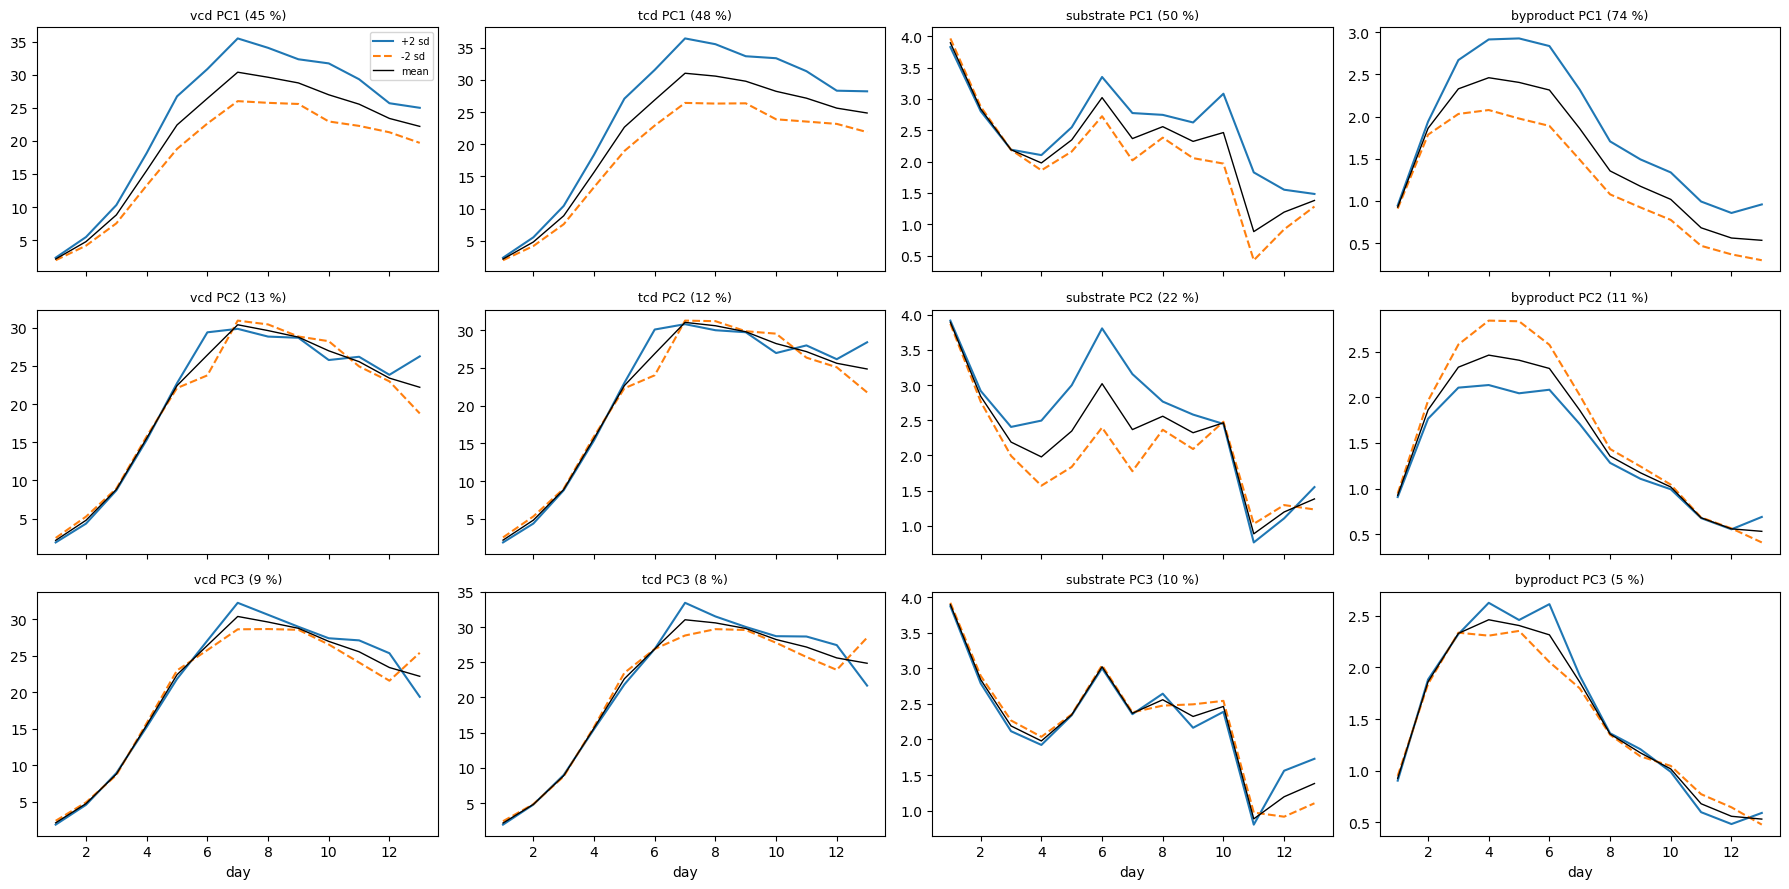

In [3]:
a_dev = to_arrays(df, dev_ids)
Z_dev = log_ratio_curves(a_dev, median_curve_preds(df, dev_ids, a_dev))
m_dev = FPCARidge(n_components=3).fit(X_all.loc[dev_ids], Z_dev)
display(m_dev.explained_variance())

days = np.arange(1, 14)
med = pd.DataFrame(np.vstack(median_curve_preds(df, dev_ids, a_dev)), columns=STATES)
med["day"] = np.tile(days, len(dev_ids)); med = med.groupby("day").mean()
fig, ax = plt.subplots(3, 4, figsize=(18, 9), sharex=True)
for c, s in enumerate(STATES):
    pc = m_dev.pca_[s]
    for r in range(3):
        sd = pc["scores"][:, r].std()
        for sign, ls in [(+2, "-"), (-2, "--")]:
            ax[r, c].plot(days, med[s] * np.exp(pc["mean"] + sign * sd * pc["comps"][r]), ls, label=f"{sign:+d} sd")
        ax[r, c].plot(days, med[s] * np.exp(pc["mean"]), "k", lw=1, label="mean")
        ax[r, c].set_title(f"{s} PC{r+1} ({100*pc['expl'][r]:.0f} %)", fontsize=9)
ax[0, 0].legend(fontsize=7); [a.set_xlabel("day") for a in ax[-1]]
plt.tight_layout(); plt.show()

## 2. One fold (quick look)

In [4]:
FOLD = 0
tr_ids = [b for b in dev_ids if fold_of[b] != FOLD]; va_ids = [b for b in dev_ids if fold_of[b] == FOLD]
t0 = time.time()
tab, objs = evaluate_split(tr_ids, va_ids, tag=f"fold{FOLD}")
print(f"{time.time()-t0:.0f} s")
tab.round(2).sort_values("all")

[fold0] mechanistic parameters from cache
1 s


,vcd,tcd,substrate,byproduct,all
median+fpca3,6.21,6.07,9.65,10.53,8.12
median+fpca2,6.29,6.14,9.88,10.48,8.19
median+fpca4_joint,6.26,6.15,10.04,10.40,8.21
mech+fpca4_joint,6.44,6.28,9.61,11.53,8.46
mech+ridge_day,6.79,6.71,9.22,11.35,8.52
mech+fpca3,6.31,6.15,11.61,11.21,8.82
mech+fpca2,6.27,6.10,11.95,11.15,8.87
median,8.16,8.11,9.97,11.93,9.54
mech,10.36,11.10,13.51,16.99,12.99


### Which inputs drive the PC scores? (median base, 2 PCs, this fold)
Standardised ridge coefficients: e.g. a large positive coefficient of `log0_vcd` on VCD-PC1 = batches that start with more cells have a higher curve.

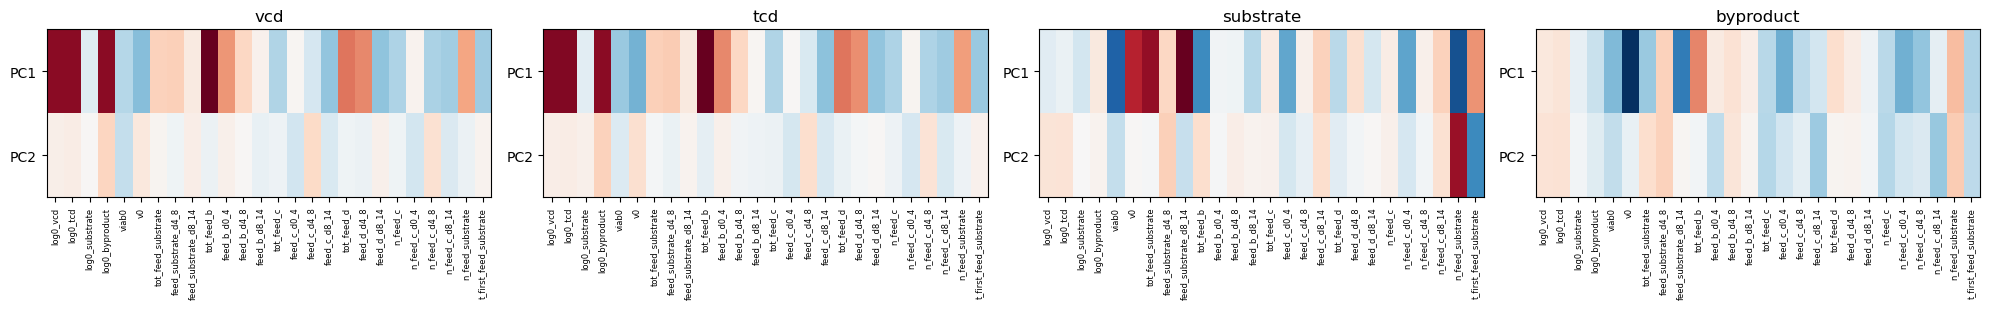

In [5]:
m_int = objs["median+fpca2"][0]
fig, ax = plt.subplots(1, 4, figsize=(20, 3.2))
for a, s in zip(ax, STATES):
    C = m_int.score_coefficients(s)
    lim = np.abs(C.values).max()
    a.imshow(C.values, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim)
    a.set_yticks(range(len(C))); a.set_yticklabels(C.index)
    a.set_xticks(range(C.shape[1])); a.set_xticklabels(C.columns, rotation=90, fontsize=6); a.set_title(s)
plt.tight_layout(); plt.show()

## 3. 5-fold cross-validation

In [8]:
RUN_CV = True
if RUN_CV:
    tabs = []
    for f in range(5):
        tr_ = [b for b in dev_ids if fold_of[b] != f]; va_ = [b for b in dev_ids if fold_of[b] == f]
        t_, _ = evaluate_split(tr_, va_, tag=f"fold{f}")
        tabs.append(t_.assign(fold=f)); print(f"fold {f}:", t_["all"].round(2).to_dict())
    cv = pd.concat(tabs).rename_axis("variant").reset_index()
    cv.to_csv(ROOT / "outputs" / "cv_scores_fpca.csv", index=False)
    display(cv.groupby("variant")[STATES + ["all"]].agg(["mean", "std"]).round(2).sort_values(("all", "mean")))

[fold0] mechanistic parameters from cache
fold 0: {'median': 9.54, 'mech': 12.99, 'mech+ridge_day': 8.52, 'median+fpca2': 8.19, 'median+fpca3': 8.12, 'mech+fpca2': 8.87, 'mech+fpca3': 8.82, 'median+fpca4_joint': 8.21, 'mech+fpca4_joint': 8.46}
[fold1] mechanistic parameters from cache
fold 1: {'median': 10.38, 'mech': 13.14, 'mech+ridge_day': 9.1, 'median+fpca2': 9.79, 'median+fpca3': 9.85, 'mech+fpca2': 9.24, 'mech+fpca3': 9.22, 'median+fpca4_joint': 9.43, 'mech+fpca4_joint': 8.8}
[fold2] mechanistic parameters from cache
fold 2: {'median': 10.07, 'mech': 13.78, 'mech+ridge_day': 10.46, 'median+fpca2': 9.31, 'median+fpca3': 9.33, 'mech+fpca2': 10.18, 'mech+fpca3': 10.17, 'median+fpca4_joint': 9.58, 'mech+fpca4_joint': 10.17}
[fold3] mechanistic parameters from cache
fold 3: {'median': 12.0, 'mech': 14.27, 'mech+ridge_day': 11.52, 'median+fpca2': 12.44, 'median+fpca3': 12.27, 'mech+fpca2': 12.55, 'mech+fpca3': 12.46, 'median+fpca4_joint': 11.7, 'mech+fpca4_joint': 11.96}
[fold4] mechan

vcd          tcd       substrate       byproduct        \
                     mean   std   mean   std      mean   std      mean   std   
variant                                                                        
median+fpca4_joint   7.37  0.84   7.30  0.90     11.43  1.70     12.76  4.16   
mech+fpca4_joint     7.37  0.85   7.26  0.91     11.13  1.21     13.50  3.96   
median+fpca3         7.29  0.79   7.19  0.85     11.36  1.63     13.53  5.03   
median+fpca2         7.27  0.77   7.13  0.81     11.38  1.50     13.64  5.32   
mech+ridge_day       7.92  1.03   7.86  1.10     10.92  1.83     13.10  2.69   
mech+fpca3           7.33  0.87   7.20  0.90     11.41  1.06     14.35  5.17   
mech+fpca2           7.33  0.88   7.20  0.91     11.45  1.14     14.45  5.44   
median               8.58  0.55   8.65  0.59     11.69  1.40     13.04  2.79   
mech                10.77  0.50  11.62  0.72     15.09  1.68     16.79  2.66   

                      all        
                     mean   std  
variant                          
median+fpca4_joint   9.71  1.26  
mech+fpca4_joint     9.82  1.38  
median+fpca3         9.84  1.52  
median+fpca2         9.86  1.57  
mech+ridge_day       9.95  1.17  
mech+fpca3          10.08  1.42  
mech+fpca2          10.11  1.45  
median              10.49  0.92  
mech                13.57  0.52

## 4. Hold-out check — once, after choosing the variant from CV

In [7]:
RUN_HOLDOUT = True
if RUN_HOLDOUT:
    tab_h, _ = evaluate_split(dev_ids, hold_ids, tag="dev_all")
    display(tab_h.round(2).sort_values("all"))

[dev_all] mechanistic parameters from cache


,vcd,tcd,substrate,byproduct,all
mech+fpca2,6.22,6.21,6.99,8.35,6.94
mech+fpca3,6.30,6.25,6.90,8.45,6.98
mech+fpca4_joint,6.34,6.28,6.92,8.48,7.01
median+fpca2,6.12,6.10,9.07,8.18,7.37
mech+ridge_day,6.89,6.98,7.32,8.58,7.44
median+fpca3,6.44,6.16,9.15,8.20,7.49
median+fpca4_joint,6.29,6.20,9.44,8.66,7.65
median,8.94,8.99,10.37,8.54,9.21
mech,10.76,10.93,12.50,12.32,11.63


## 5. Final: fit on all 49 batches → submission

In [9]:
RUN_FINAL = True
BASE, K, JOINT = "mech", 2, False     # choose from the CV result
if RUN_FINAL:
    a_all = to_arrays(df, train_ids)
    a_test = to_arrays(df, test_ids, sample_mask="predict")
    if BASE == "mech":
        p_all = mech_params(train_ids, tag="all49")
        b_all, b_test = predict_at_obs(p_all, a_all), predict_at_obs(p_all, a_test)
    else:
        b_all, b_test = median_curve_preds(df, train_ids, a_all), median_curve_preds(df, train_ids, a_test)
    m = FPCARidge(n_components=K, joint=JOINT).fit(X_all.loc[a_all.ids], log_ratio_curves(a_all, b_all))
    preds = to_pred_list(a_test, b_test, m.predict(X_all.loc[a_test.ids]))
    failed = [b for b, y in zip(a_test.ids, preds) if np.isnan(y).any()]
    assert not failed, f"NaN predictions for {failed}"

    pred_of = {b: (ts, ys) for b, ts, ys in zip(a_test.ids, a_test.obs_t, preds)}
    sub = tmpl.copy(); sub[STATES] = sub[STATES].astype(float)   # template columns are int zeros
    for b, g in sub.groupby("batch_id", sort=False):
        ts, ys = pred_of[b]; order = np.argsort(ts)
        assert len(g) == len(ts) and np.allclose(np.sort(g.elapsed_time.values), ts[order], atol=1e-3), b
        sub.loc[g.sort_values("elapsed_time").index, STATES] = ys[order]
    assert sub[STATES].notna().all().all() and (sub[STATES] > 0).all().all()
    out = ROOT / "outputs" / f"submission_{fpca_name(BASE, K, JOINT).replace('+', '_')}.csv"
    sub.to_csv(out, index=False); print("written", out)
    display(sub.head())

[all49] mechanistic parameters from cache
written f:\hackathon\main\outputs\submission_mech_fpca2.csv


,batch_id,elapsed_time,vcd,tcd,substrate,byproduct
0,Batch5,0.965972,2.490900,2.519586,3.867478,1.075370
1,Batch5,1.948611,5.574291,5.642780,2.680388,2.058829
2,Batch5,2.940278,10.193448,10.288979,1.930416,2.444209
3,Batch5,3.919444,17.634169,17.807716,1.707991,2.492355
4,Batch5,4.924306,25.384102,25.735877,1.970165,2.346937
